# Лабораторна робота 3
## Класифікація текстів: Human vs AI

### 1. Імпорт бібліотек
Підключаємо `pandas`, `matplotlib` та `numpy` для роботи з даними й побудови графіків, а також фіксуємо `random_seed` для відтворюваності результатів.

In [123]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

random_seed = 42

### 2. Завантаження даних
Читаємо датасет `ai_vs_human_text_2026.csv` з текстами, написаними людиною та ШІ.

In [124]:
data = pd.read_csv("ai_vs_human_text_2026.csv")

### 3. Первинний огляд даних

**3.1. Перші рядки таблиці.** Знайомимось зі структурою датасету та змістом стовпців.

In [125]:
data.head()

,text_id,label,source_model,domain,text_content,topic_hint,word_count,avg_sentence_length,generation_method
0,TXT_0001,human,human,social,can we talk about gene editing ethics for a se...,gene editing ethics,27,13.5,template+human_variation
1,TXT_0002,human,human,social,update on election integrity concerns: it's co...,election integrity concerns,20,10.0,template+human_variation
2,TXT_0003,ai,gemini-2.0,news,Analysts are closely watching developments rel...,climate change adaptation strategies,39,13.0,style_simulation
3,TXT_0004,human,human,academic,This paper examines genomic research breakthro...,genomic research breakthroughs,49,16.3,template+human_variation
4,TXT_0005,ai,gpt-4o,academic,Existing literature on student debt crisis has...,student debt crisis,42,10.8,style_simulation


**3.2. Типи даних і пропуски.** Перевіряємо кількість записів, типи стовпців та наявність пропущених значень.

In [126]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   text_id              2000 non-null   str    
 1   label                2000 non-null   str    
 2   source_model         2000 non-null   str    
 3   domain               2000 non-null   str    
 4   text_content         2000 non-null   str    
 5   topic_hint           2000 non-null   str    
 6   word_count           2000 non-null   int64  
 7   avg_sentence_length  2000 non-null   float64
 8   generation_method    2000 non-null   str    
dtypes: float64(1), int64(1), str(7)
memory usage: 140.8 KB


**3.3. Описова статистика.** Середнє, мінімум, максимум і квартилі для числових ознак (`word_count`, `avg_sentence_length`).

In [127]:
data.describe()

,word_count,avg_sentence_length
count,2000.000000,2000.000000
mean,37.006500,12.739950
std,8.892975,2.846465
min,19.000000,6.500000
25%,28.000000,10.200000
50%,38.000000,13.000000
75%,45.000000,15.300000
max,52.000000,18.500000


### 4. Розвідувальний аналіз (до очищення)

**4.1. Розподіл класів.** Скільки записів належить до класу `human`, а скільки до `ai` — перевіряємо баланс класів.

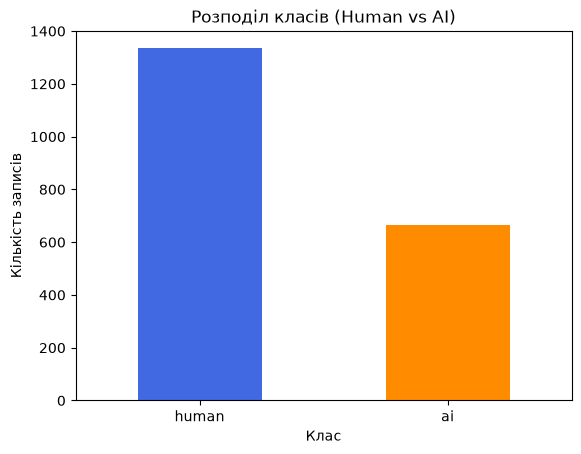

In [128]:
data['label'].value_counts().plot(kind='bar', color=['royalblue', 'darkorange'])

plt.title('Розподіл класів (Human vs AI)')
plt.xlabel('Клас')
plt.ylabel('Кількість записів')
plt.xticks(rotation=0) 
plt.show()

**4.2. Порожні тексти.** Рахуємо рядки в `text_content`, що не містять жодного символу, крім пробілів.

In [129]:
empty_strings = (data['text_content'].str.strip() == '').sum()
print(f"Кількість порожніх рядків: {empty_strings}")

Кількість порожніх рядків: 0


**4.3. Діапазон довжини текстів.** Мінімальна та максимальна кількість слів у тексті.

In [130]:
data["word_count"].min()

np.int64(19)

In [131]:
data["word_count"].max()

np.int64(52)

**4.4. Кількість речень.** Створюємо ознаку `num_sentences`, поділивши кількість слів на середню довжину речення та округливши вгору.

In [132]:
data["num_sentences"] = np.ceil(data["word_count"] / data["avg_sentence_length"]).astype(int)

**4.5. Розподіл кількості речень за класами.** Порівнюємо, скільки речень зазвичай містять тексти людини та ШІ.

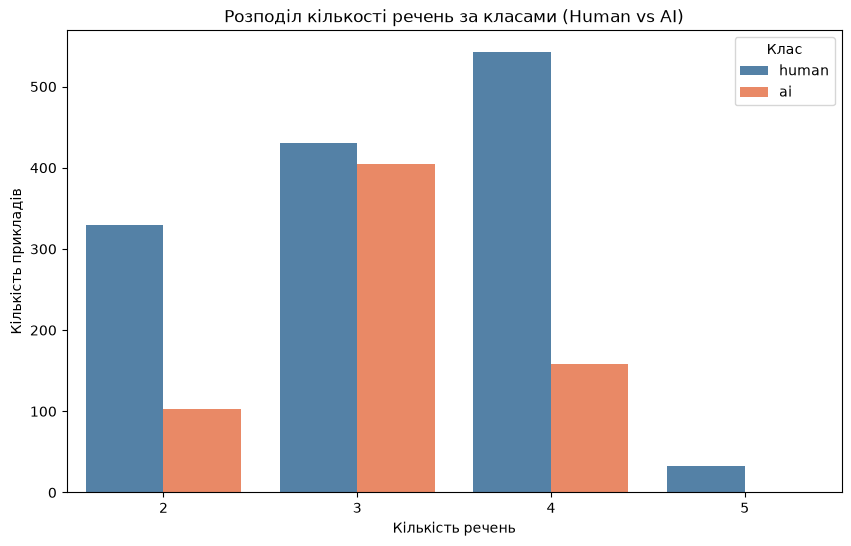

In [133]:
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.countplot(
    data=data, 
    x='num_sentences', 
    hue='label', 
    palette={'human': 'steelblue', 'ai': 'coral'}
)

plt.title('Розподіл кількості речень за класами (Human vs AI)')
plt.xlabel('Кількість речень')
plt.ylabel('Кількість прикладів')
plt.legend(title='Клас')
plt.xticks(rotation=0)
plt.show()

**4.6. Розподіл кількості слів за класами.** Гістограми з кривою щільності окремо для `human` та `ai`.

C:\Users\vital\AppData\Local\Temp\ipykernel_18948\1597368727.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend()
C:\Users\vital\AppData\Local\Temp\ipykernel_18948\1597368727.py:30: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[1].legend()


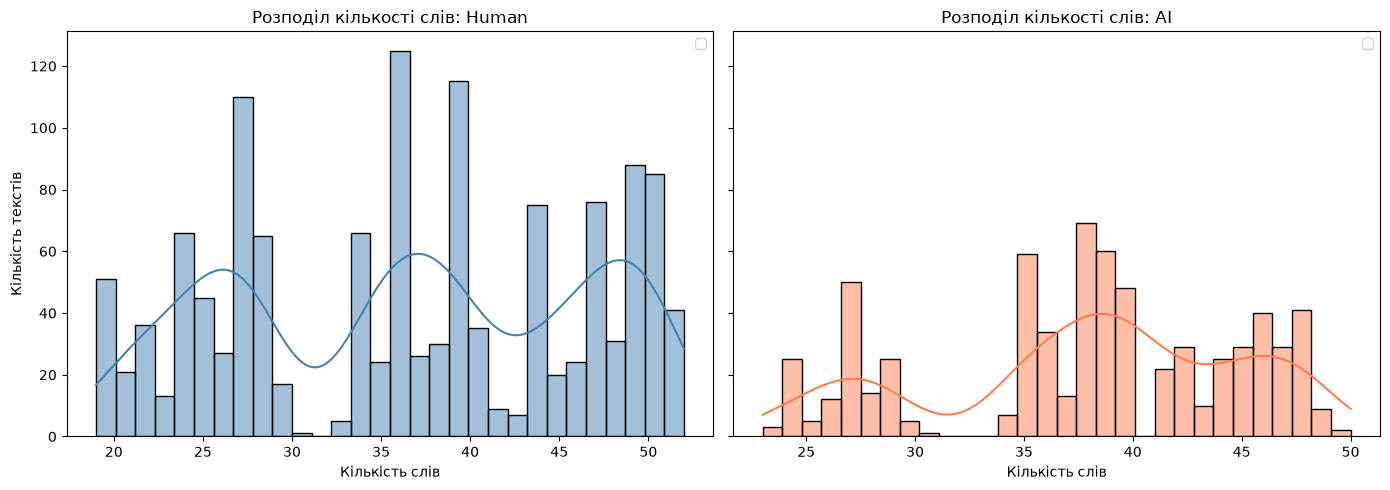

In [ ]:
mean_human = data[data['label'] == 'human']['word_count'].mean()
mean_ai = data[data['label'] == 'ai']['word_count'].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

sns.histplot(
    data[data['label'] == 'human']['word_count'], 
    ax=axes[0], 
    color='steelblue', 
    kde=True, 
    bins=30
)
axes[0].set_title('Розподіл кількості слів: Human')
axes[0].set_xlabel('Кількість слів')
axes[0].set_ylabel('Кількість текстів')
axes[0].legend()

sns.histplot(
    data[data['label'] == 'ai']['word_count'], 
    ax=axes[1], 
    color='coral', 
    kde=True, 
    bins=30
)

axes[1].set_title('Розподіл кількості слів: AI')
axes[1].set_xlabel('Кількість слів')
axes[1].legend()

plt.tight_layout()
plt.show()

### 5. Пошук дублікатів

**5.1. Дублікати текстів.** Шукаємо повторювані тексти без урахування регістру. Знайдено **1597** рядків, що мають дублікати.

In [135]:
duplicate_rows = data[data["text_content"].str.lower().duplicated(keep=False)].sort_values(by="text_content")
print(f"Знайдено рядків з дублікатами: {len(duplicate_rows)}")
duplicate_rows[["text_id", "label", "text_content"]].head()

Знайдено рядків з дублікатами: 1597


,text_id,label,text_content
695,TXT_0696,ai,A growing body of research underscores the sal...
1253,TXT_1254,ai,A growing body of research underscores the sal...
490,TXT_0491,ai,A growing body of research underscores the sal...
931,TXT_0932,ai,A growing body of research underscores the sal...
1327,TXT_1328,ai,A growing body of research underscores the sal...


**5.2. Дублікати за класами.** Розподіл повторюваних текстів між `human` та `ai`.

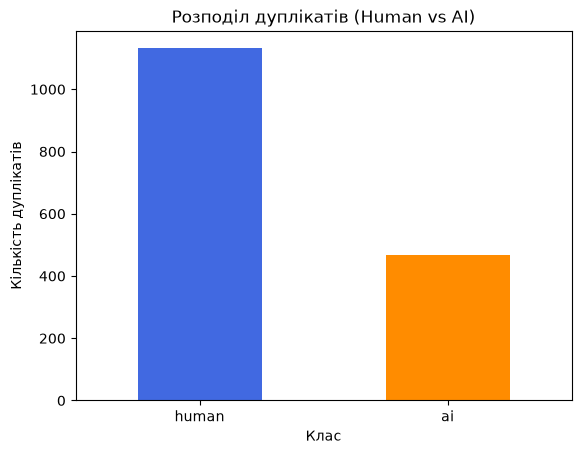

In [136]:
duplicate_rows['label'].value_counts().plot(kind='bar', color=['royalblue', 'darkorange'])

plt.title('Розподіл дуплікатів (Human vs AI)')
plt.xlabel('Клас')
plt.ylabel('Кількість дуплікатів')
plt.xticks(rotation=0) 
plt.show()

### 6. Очищення даних
Видаляємо дублікати (за текстом, приведеним до нижнього регістру й без зайвих пробілів), залишаючи по одному екземпляру. Розмір датасету зменшується з **2000** до **942** записів.

In [137]:
print(f"Розмір до видалення дублікатів: {len(data)}")
data['clean_text_temp'] = data['text_content'].str.lower().str.strip()

data = data.drop_duplicates(subset=['clean_text_temp']).reset_index(drop=True)

data = data.drop(columns=['clean_text_temp'])
print(f"Розмір після видалення дублікатів: {len(data)}")

Розмір до видалення дублікатів: 2000
Розмір після видалення дублікатів: 942


### 7. Повторний аналіз після очищення

**7.1. Розподіл класів.** Перевіряємо, як видалення дублікатів вплинуло на баланс класів.

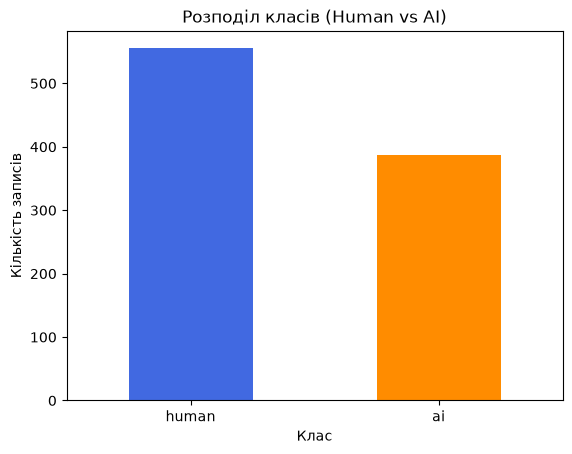

In [138]:
data['label'].value_counts().plot(kind='bar', color=['royalblue', 'darkorange'])

plt.title('Розподіл класів (Human vs AI)')
plt.xlabel('Клас')
plt.ylabel('Кількість записів')
plt.xticks(rotation=0) 
plt.show()

**7.2. Розподіл кількості речень за класами** після видалення дублікатів.

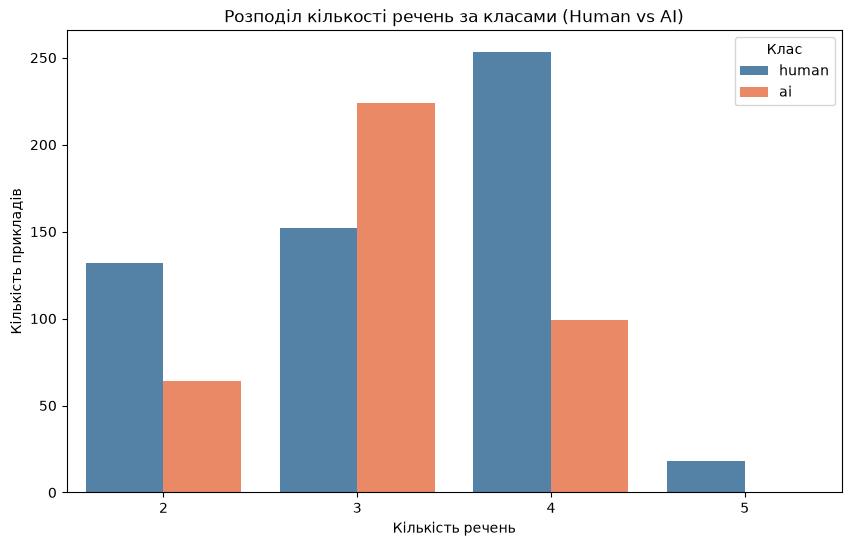

In [139]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=data, 
    x='num_sentences', 
    hue='label', 
    palette={'human': 'steelblue', 'ai': 'coral'}
)

plt.title('Розподіл кількості речень за класами (Human vs AI)')
plt.xlabel('Кількість речень')
plt.ylabel('Кількість прикладів')
plt.legend(title='Клас')
plt.xticks(rotation=0)
plt.show()

**7.3. Розподіл кількості слів за класами** після видалення дублікатів.

C:\Users\vital\AppData\Local\Temp\ipykernel_18948\2105383708.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend()
C:\Users\vital\AppData\Local\Temp\ipykernel_18948\2105383708.py:29: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[1].legend()


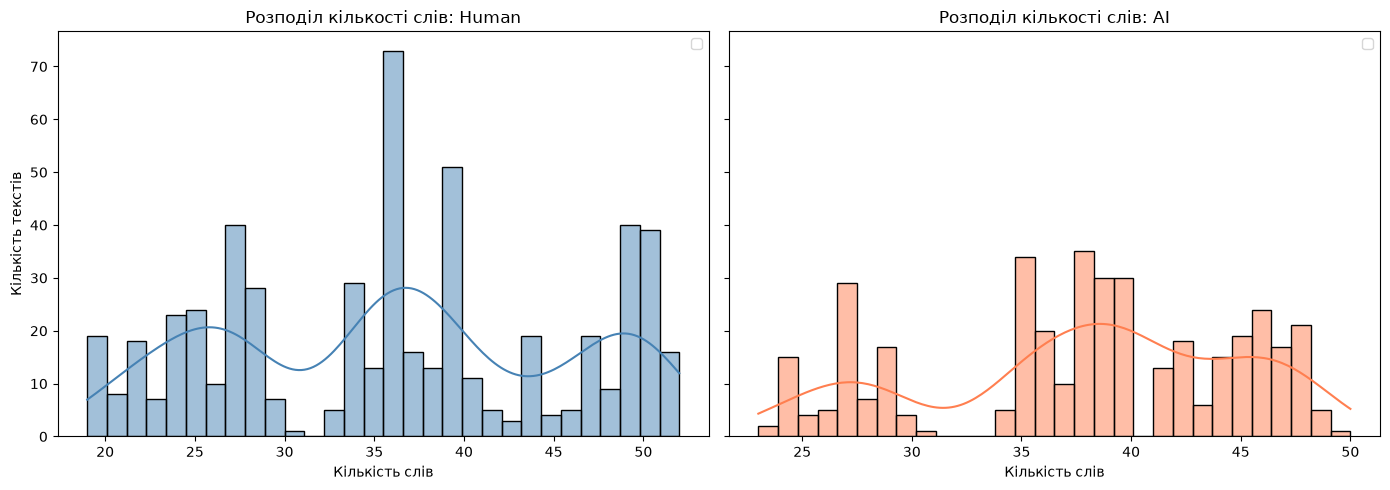

In [ ]:
mean_human = data[data['label'] == 'human']['word_count'].mean()
mean_ai = data[data['label'] == 'ai']['word_count'].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

sns.histplot(
    data[data['label'] == 'human']['word_count'], 
    ax=axes[0], 
    color='steelblue', 
    kde=True, 
    bins=30
)
axes[0].set_title('Розподіл кількості слів: Human')
axes[0].set_xlabel('Кількість слів')
axes[0].set_ylabel('Кількість текстів')
axes[0].legend()

sns.histplot(
    data[data['label'] == 'ai']['word_count'], 
    ax=axes[1], 
    color='coral', 
    kde=True, 
    bins=30
)

axes[1].set_title('Розподіл кількості слів: AI')
axes[1].set_xlabel('Кількість слів')
axes[1].legend()

plt.tight_layout()
plt.show()

### 8. Збереження результату
Зберігаємо очищений датасет (колонки `text_content` та `label`) у файл `data.csv` для подальшого навчання моделей.

In [141]:
data[["text_content", "label"]].reset_index().to_csv('data.csv')